# Figure 9: lazy-regime network on Pile token statistics

Camera-ready version of the appendix Figure 9 (`fig:pile-lazy`, file `figures/FigureA4.pdf`). The first cells draw the figure from `tangent_sweeps.npz` and `cnt_raw.npy` and reproduce the fitted exponents: left panel, $\alpha_D=1.156$, $1.277$, $1.292$, $1.267$ at $H=8$, $32$, $128$, $1024$; right panel, at $H=8$, corrected $\alpha_N=1.054$ (sparse) and $-0.072$ (dense). Only the unobserved-variance line in the left panel is recomputed, from the counts, in seconds.

Printed size $5.5\times1.9$ in (`\textwidth`): tick labels 7 pt, axis labels 8 pt, titles 9 pt, legend in the left panel 6 pt, in-plot labels in the right panel 7 pt.

The cells under *Experiment* are the original experiment, a depth-3 ReLU network on an $N$-dimensional random projection, linearized at initialization. With `tangent_sweeps.npz` present they load the sweeps; without it they recompute them (one GPU, about 9 minutes).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.transforms as mtransforms

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt); the figure is drawn at its size on the page
FIG_W, FIG_H = 5.5, 1.9          # inches
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 7, 8, 9, 7

def style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=FS_LABEL, labelpad=1)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1)
    ax.tick_params(which="both", labelsize=FS_TICK, pad=1.5)
    ax.tick_params(which="major", length=2.5)
    ax.tick_params(which="minor", length=1.5)

gmean = lambda Y: np.exp(np.log(Y).mean(0))                       # geometric mean over seeds
gse   = lambda Y: gmean(Y) * np.log(Y).std(0) / np.sqrt(Y.shape[0])
slope = lambda x, Y: -np.polyfit(np.log(np.asarray(x, float)), np.log(Y).mean(0), 1)[0]

In [2]:
# Data: counts, specified amplitudes, and the cached sweeps
SEED = 20260731                                   # master seed of the experiment below
rng_for = lambda purpose, seed: np.random.default_rng([SEED, purpose, seed])
c = np.sort(np.load("cnt_raw.npy").astype(np.float64))[::-1]; c = c[c > 0]
M = c.size; p = c / c.sum()
amp = np.arange(1, M + 1, dtype=np.float64) ** (-(0.3 + 1) / 2)
var = p * amp**2

t = np.load("tangent_sweeps.npz")
WIDTHS, D_LADDER, H_C = [int(h) for h in t["WIDTHS"]], t["D_LADDER"], int(t["H_C"])
N_L_C, K_N, D_CTRL = t["N_L_C"], float(t["K_N"]), int(t["D_CTRL"])
P_C  = N_L_C * H_C + H_C**2 + H_C                 # trainable parameters at each rung
fit  = P_C <= 0.5 * K_N                           # fit window used in the paper
N_FIT = N_L_C[fit]
infl = 1 / (1 - P_C[fit] / D_CTRL)                # finite-sample correction, common to both designs
sF, dF = t["sN"][:, fit] / infl, t["dN"][:, fit] / infl
# variance of the coordinates never observed among D samples (same draws as the sweep)
unobs = np.array([[var[rng_for(22, s * 1000 + int(D)).multinomial(int(D), p) == 0].sum()
                   for D in D_LADDER] for s in range(3)])
for H in WIDTHS:
    print(f"H = {H:5d}   alpha_D {slope(D_LADDER, t[f'resD_{H}']):.3f}")

H =     8   alpha_D 1.156
H =    32   alpha_D 1.277
H =   128   alpha_D 1.292
H =  1024   alpha_D 1.267


sparse  alpha_N (corrected) 1.054
dense   alpha_N (corrected) -0.072


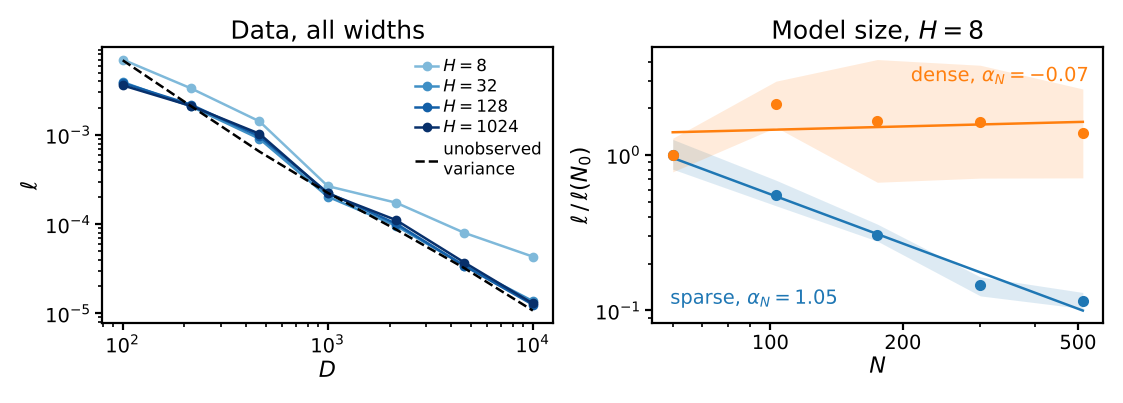

In [3]:
# FIGURE 9 (FigureA4.pdf): left, data axis at all widths; right, model-size axis at H = 8
figA4, (A, B) = plt.subplots(1, 2, figsize=(FIG_W, FIG_H), layout="constrained")
for H, color in zip(WIDTHS, plt.cm.Blues(np.linspace(0.45, 1.0, len(WIDTHS)))):
    A.loglog(D_LADDER, gmean(t[f"resD_{H}"]), "o-", ms=2.5, lw=0.9, color=color, label=f"$H={H}$")
A.loglog(D_LADDER, gmean(unobs), "k--", lw=0.9, label="unobserved\nvariance")
A.xaxis.set_minor_formatter(ticker.NullFormatter())
A.set_title("Data, all widths", fontsize=FS_TITLE, pad=3)
style(A, "$D$", r"$\ell$")
A.legend(loc="upper right", fontsize=FS_LEGEND - 1, frameon=False, handlelength=1.4,
         handletextpad=0.3, borderaxespad=0.3, labelspacing=0.2)

for Y, color, name, xy, ha in ((sF, "C0", "sparse", (0.04, 0.05), "left"),
                               (dF, "C1", "dense", (0.97, 0.93), "right")):
    g = gmean(Y); k = g[0]
    cf = np.polyfit(np.log(N_FIT), np.log(g), 1)
    print(f"{name:7s} alpha_N (corrected) {-cf[0]:.3f}")
    B.fill_between(N_FIT, Y.min(0) / k, Y.max(0) / k, color=color, alpha=.15, lw=0)
    B.loglog(N_FIT, g / k, "o", ms=3, color=color)
    B.loglog(N_FIT, np.exp(np.polyval(cf, np.log(N_FIT))) / k, "-", lw=0.9, color=color)
    B.text(*xy, rf"{name}, $\alpha_N={-cf[0]:.2f}$", color=color, fontsize=FS_LEGEND, ha=ha,
           va="bottom" if ha == "left" else "top", transform=B.transAxes)
B.xaxis.set_major_locator(ticker.FixedLocator([100, 200, 500]))
B.xaxis.set_major_formatter(ticker.FormatStrFormatter("%d"))
B.xaxis.set_minor_locator(ticker.FixedLocator([60, 70, 80, 90, 300, 400]))
B.xaxis.set_minor_formatter(ticker.NullFormatter())
B.set_title(f"Model size, $H={H_C}$", fontsize=FS_TITLE, pad=3)
style(B, "$N$", r"$\ell\,/\,\ell(N_0)$")
figA4.savefig("../figures/FigureA4.pdf")
figA4.savefig("../figures/FigureA4.png", dpi=300)
plt.show()

## Experiment

The original experiment notebook, kept as run. Its printed outputs are from that run; the figure above does not depend on running these cells.

# Linearized deep network on Pile token indicators

A depth-3 ReLU MLP of width $H$ applied to an $N$-dimensional random projection,
linearized at initialisation and trained to completion. A linearized model is linear
in its parameters, so "trained to completion" is ridgeless regression in the tangent
kernel: the solution is solved for, not approached, and there is no optimizer, no
learning rate and no convergence guard.

$$x \;\to\; ux\;(N) \;\to\; \mathrm{ReLU}\;(H) \;\to\; \mathrm{ReLU}\;(H) \;\to\; \text{scalar}$$

Trainable parameter count $P = NH + H^2 + H$. The projection is not optional: on raw
one-hot inputs distinct tokens are orthogonal and the ReLU tangent kernel reduces to
rank one plus diagonal, so depth does nothing by construction. The gate verifies this.

### Data

Token counts from the Pile under a 200k-token vocabulary: 147,775 observed types over
148,282,604 tokens. Coordinate $j$ activates with its measured unigram probability
$p_j$; the amplitude exponent $\alpha_2 = 0.3$ and the target weights are specified,
not fitted. Only the activation pattern and its frequency law come from the corpus.

### Design condition

The model-size axis is informative only while $P < K(D)$. Once the parameter count
exceeds the number of observed coordinates the model interpolates the token table and
the loss floors, so a fitted slope measures the floor rather than capacity. At the
operating point below this holds across a usable $N$ range only at $H = 8$, and the
$P/K$ table printed by the operating-point cell shows why. The data axis has
$P \gg K(D)$ at every width and is measured at all four.

### What is measured

1. **Model size, $H = 8$.** Sparse $\alpha_N$ against a dense control on the same
   $N$ ladder, with the dense arm's sample count matched to the sparse arm's $K(D)$.
2. **Data, all widths.** $\alpha_D$ against the parameter-free unobserved-variance
   line, across $128\times$ in width.

### Scope

The dense control is used on the model-size axis only, where its $P/D$ equals the
sparse arm's $P/K$ by construction. Propositions 3.1 and 3.5 of the paper are results
for the linear random-feature model; they are not asserted to hold for a linearized
network, and nothing below depends on them.

### Seeds and ladders

The random projection is drawn on the accelerator, so its stream depends on the
device: exponents reproduce exactly on fixed hardware and shift in the second decimal
across different GPUs, in the same way a change of seed would. The reported intervals
are over seeds and cover this.

3 seeds sparse, 2 dense. $N$ ladder: 7 rungs over 1.40 decades, restricted by
$P < K$ to 6 rungs spanning 60–877 (1.16 decades). $D$ ladder: 7 rungs over 2.00
decades. All intervals are bootstrap percentiles over seeds.

Sweep results are written to `tangent_sweeps.npz` as soon as they exist. If the file
is present the sweep cells load from it; delete it to recompute from scratch. A full
recompute is about nine minutes on one GPU.

## 1. Setup

Backend selection, the master seed, and an execution-order guard. Every random draw
comes from `rng_for(purpose, seed)`, which derives an independent generator from the
master seed, so results do not depend on the order in which cells are run.

In [2]:
import numpy as np, time, os
import matplotlib.pyplot as plt

CFG  = dict(alpha2=0.3, rcond=1e-10, seed=20260731)
CKPT = "."
rng_for = lambda purpose, seed: np.random.default_rng([CFG["seed"], purpose, seed])
_ran = set()
def done(c): _ran.add(c)
def require(*cs):
    m = [c for c in cs if c not in _ran]
    if m: raise RuntimeError(f"run cell(s) {m} first")
try:
    import cupy as cp; xp, GPU = cp, True
except ImportError:
    xp, GPU = np, False
to_np = lambda a: np.asarray(a.get() if hasattr(a, "get") else a)
def free():
    if GPU: cp.get_default_memory_pool().free_all_blocks()
SQ2 = np.sqrt(2.0)
print("gpu" if GPU else "cpu"); done(0)

gpu


## 2. Corpus counts, activation law, and the results store

`p` is the measured unigram probability of each coordinate, `amp` the specified
amplitude, `var` the per-coordinate variance. `K_of(D)` is the expected number of
distinct coordinates observed in $D$ draws, $\sum_j (1 - e^{-D p_j})$.

`stash()` merges arrays into the store and replaces it atomically, so a crash or a
disconnect mid-notebook cannot leave a half-written file. Sweep cells call it the
moment their results exist rather than at the end of the notebook.

Set `DATA_DIR` at the top of the cell to the folder holding `cnt_raw.npy`. Everything
else is derived; there are no other paths in the notebook.

**Check the absolute path this cell prints.** If it is not on persistent storage the
results will not survive a runtime restart.

In [3]:
require(0)
# ---- configuration: the only path in this notebook --------------------------
DATA_DIR   = "."                       # folder holding cnt_raw.npy
MOUNTED_AT = "/content/drive/MyDrive"  # used only if DATA_DIR has no counts and
SUBFOLDER  = "alphaN_ckpt"            # a hosted-notebook drive can be mounted
# -----------------------------------------------------------------------------
if not os.path.exists(f"{DATA_DIR}/cnt_raw.npy"):
    try:
        from google.colab import drive; drive.mount(os.path.dirname(MOUNTED_AT))
        DATA_DIR = f"{MOUNTED_AT}/{SUBFOLDER}"
    except Exception:
        pass
assert os.path.exists(f"{DATA_DIR}/cnt_raw.npy"), (
    f"cnt_raw.npy not found under {DATA_DIR!r}; set DATA_DIR above")
cnt_raw = np.load(f"{DATA_DIR}/cnt_raw.npy")

c     = np.sort(cnt_raw.astype(np.float64))[::-1]; c = c[c > 0]
M     = c.size
n_tok = int(c.sum())
p     = c / c.sum()
amp   = np.arange(1, M+1, dtype=np.float64) ** (-(CFG["alpha2"]+1)/2)
var   = p * amp**2

def K_of(D):
    D = np.atleast_1d(np.asarray(D, float))
    return np.array([float((1-np.exp(-d*p)).sum()) for d in D])
def D_for(K, lo=10.0, hi=None):
    g = np.logspace(np.log10(lo), np.log10(hi or 0.9/p.min()), 3000)
    return float(g[np.argmin(np.abs(K_of(g)-K))])

_cand = ["tangent_sweeps.npz", f"{DATA_DIR}/tangent_sweeps.npz"]
STORE = next((q for q in _cand if os.path.exists(q)), f"{DATA_DIR}/tangent_sweeps.npz")

def load_store():
    if not os.path.exists(STORE): return None
    with np.load(STORE) as z: return {k: z[k] for k in z.files}

def stash(**kw):
    '''Merge arrays into STORE and replace it atomically.'''
    global CACHE
    cur = load_store() or {}
    cur.update({k: np.asarray(v) for k, v in kw.items()})
    tmp = STORE + ".tmp.npz"
    np.savez_compressed(tmp, **cur); os.replace(tmp, STORE)
    CACHE = cur
    print(f"  stashed {sorted(kw)} -> {os.path.abspath(STORE)} "
          f"({os.path.getsize(STORE)/1e6:.2f} MB, {len(cur)} arrays)")

CACHE = load_store()
_abs  = os.path.abspath(STORE)
print(f"store: {_abs}")
if _abs.startswith("/content/") and "/drive/" not in _abs:
    print("  WARNING: this path is wiped when the runtime restarts")
print("  " + (f"present, {len(CACHE)} arrays -- sweeps will load"
              if CACHE else "absent -- sweeps will compute (~9 min on one GPU)"))
print(f"{M:,} observed types, {n_tok:,} tokens"); done(1)

Mounted at /content/drive
store: /content/drive/MyDrive/alphaN_ckpt/tangent_sweeps.npz
  present, 15 arrays -- sweeps will load
147,775 observed types, 148,282,604 tokens


## 3. Feature map, tangent kernel, and the two solvers

`emp_ntk` evaluates the finite-width empirical tangent kernel through

$$\Theta(a,b) = \sum_{l} \frac{(d^a_l \cdot d^b_l)\,(h^a_{l-1} \cdot h^b_{l-1})}{\dim_{l-1}}$$

so the $P$-dimensional tangent features are never formed and the cost does not grow
with $P$. That is what makes width 1024 affordable.

`tangent_loss` is the sparse arm: the design is determined by per-coordinate counts,
the solve is count-weighted min-norm least squares, and the returned loss is the exact
population loss summed over all $M$ coordinates rather than a test-set estimate.
`dense_tangent` is the dense control: a Gaussian design with matched second moments,
ridgeless, with a Monte-Carlo test loss on 20,000 fresh samples. `linear_loss` exists
only as the depth-1 reference the gate checks against.

In [4]:
require(0, 1)
DEPTH = 3                                    # weight matrices; DEPTH-1 hidden layers

def make_u(Nmax, seed, chunk=4096):
    g = np.random.default_rng(seed) if xp is np else cp.random.default_rng(seed)
    u = xp.empty((Nmax, M), dtype=xp.float32)
    for i in range(0, Nmax, chunk):
        k = min(chunk, Nmax-i)
        u[i:i+k] = g.standard_normal((k, M), dtype=xp.float32)/np.sqrt(Nmax)
    return u

Z_of = lambda u, N, idx: (u[:N, xp.asarray(idx)].astype(xp.float64)
                          * xp.asarray(amp[idx])).T          # (len(idx), N)

def net_feats(Z, H, seed):
    '''Forward and backward at initialisation. NTK parameterisation, He scaling.'''
    r = np.random.default_rng(seed); n, N = Z.shape
    dims = [N] + [H]*(DEPTH-1)
    Ws = [xp.asarray(r.standard_normal((H, dims[l]))) for l in range(DEPTH-1)]
    wo = xp.asarray(r.standard_normal(dims[-1]))
    A, Hs, h = [], [], Z
    for l in range(DEPTH-1):
        a = h @ Ws[l].T * SQ2/np.sqrt(dims[l]); h = xp.maximum(a, 0)
        A.append(a); Hs.append(h)
    g = xp.broadcast_to(wo/np.sqrt(dims[-1]), (n, dims[-1])).copy()
    Ds = [None]*(DEPTH-1)
    for l in range(DEPTH-2, -1, -1):
        Ds[l] = g*(A[l] > 0)
        if l > 0: g = Ds[l] @ Ws[l] * SQ2/np.sqrt(dims[l])
    return Hs, Ds, dims

def emp_ntk(Za, Zb, H, seed, Gz):
    '''Empirical tangent kernel. The P-dimensional features are never formed.'''
    if DEPTH == 1: return Gz / Za.shape[1]
    Ha, Da, dims = net_feats(Za, H, seed)
    Hb, Db, _    = net_feats(Zb, H, seed)
    K = Ha[-1] @ Hb[-1].T / dims[-1]
    for l in range(DEPTH-1):
        inner = Gz if l == 0 else (Ha[l-1] @ Hb[l-1].T)
        K = K + (Da[l] @ Db[l].T) * inner * 2.0/dims[l]
    return K

def tangent_loss(u, N, counts, w, H, seed=7, block=4096):
    '''Sparse arm: count-weighted min-norm tangent regression, exact population loss.'''
    obs = np.flatnonzero(counts > 0); sq = xp.asarray(np.sqrt(counts[obs]))
    Zo  = Z_of(u, N, obs); Gz = Zo @ Zo.T
    Th  = emp_ntk(Zo, Zo, H, seed, Gz)
    Tw  = Th * (sq[:, None]*sq[None, :]); del Th
    ev, V = xp.linalg.eigh((Tw + Tw.T)/2); del Tw
    keep = ev > CFG["rcond"]*ev[-1]; Vk = V[:, keep]
    y  = xp.asarray(amp[obs]*w[obs])
    al = sq * (Vk @ ((Vk.T @ (sq*y))/ev[keep])); del V, Vk; free()
    loss = 0.0
    for i in range(0, M, block):
        idx = np.arange(i, min(i+block, M))
        Zb  = Z_of(u, N, idx); Gb = Zb @ Zo.T
        Tb  = emp_ntk(Zb, Zo, H, seed, Gb)
        loss += float((p[idx]*(amp[idx]*w[idx] - to_np(Tb @ al))**2).sum()); del Tb, Zb
    free(); return loss

def linear_loss(u, N, counts, w):
    '''Depth-1 reference used by the gate.'''
    obs = np.flatnonzero(counts > 0); g = np.sqrt(counts[obs])*amp[obs]
    B = u[:N, xp.asarray(obs)].astype(xp.float64) * xp.asarray(g)
    U, S, Vt = xp.linalg.svd(B, full_matrices=False); k = S > CFG["rcond"]*S[0]
    th = to_np((U[:,k]/S[k]) @ (Vt[k] @ xp.asarray(g*w[obs])))
    what = np.empty(M)
    for i in range(0, M, 4096):
        what[i:i+4096] = to_np(u[:N, i:i+4096].astype(xp.float64).T @ xp.asarray(th))
    return float((var*(w-what)**2).sum())

def dense_batch(u, N, D, wd, seed, chunk=2048):
    '''Z = X u^T and y = X w with X ~ N(0, diag(var)), generated in row chunks.'''
    g  = np.random.default_rng(seed) if xp is np else cp.random.default_rng(seed)
    sd, wx = xp.asarray(np.sqrt(var)), xp.asarray(wd)
    Z = xp.empty((D, N), xp.float64); y = xp.empty(D, xp.float64)
    for i in range(0, D, chunk):
        k = min(chunk, D - i)
        X = g.standard_normal((k, M), dtype=xp.float32).astype(xp.float64) * sd
        Z[i:i+k] = X @ u[:N].astype(xp.float64).T
        y[i:i+k] = X @ wx
        del X
    return Z, y

def dense_tangent(u, N, D, wd, H, seed, ntest=20_000):
    '''Dense control: ridgeless tangent regression, Monte-Carlo test loss.'''
    Ztr, ytr = dense_batch(u, N, D, wd, [seed, 1])
    Th = emp_ntk(Ztr, Ztr, H, seed, Ztr @ Ztr.T)
    ev, V = xp.linalg.eigh((Th + Th.T)/2); del Th
    keep = ev > CFG["rcond"]*ev[-1]; Vk = V[:, keep]
    al = Vk @ ((Vk.T @ ytr)/ev[keep]); del V, Vk; free()
    Zte, yte = dense_batch(u, N, ntest, wd, [seed, 2])
    pred = emp_ntk(Zte, Ztr, H, seed, Zte @ Ztr.T) @ al
    out = float(to_np(((yte - pred)**2).mean())); del Ztr, Zte; free()
    return out
done(2)

## 4. Gate

Three checks, all asserted rather than eyeballed.

1. **Depth 1 reproduces the linear random-feature model.** Setting `DEPTH = 1` should
   make `tangent_loss` and `linear_loss` agree to machine precision on real data. This
   is the check that the tangent kernel and the He scaling are right; an error in
   either shows up here as a mismatch of order one, not order $10^{-13}$.
2. **The kernel concentrates as width grows.** Seed-to-seed spread of the empirical
   kernel, measured as $\|\mathrm{sd}\|_F / \|\mathrm{mean}\|_F$ over six draws, must
   fall by at least half across the $64\times$ width range.
3. **Orthogonal inputs give rank one plus diagonal.** All off-diagonal entries equal,
   which is why the random projection is required and why a linearized network on raw
   token indicators would be a lookup table plus one shared direction.

In [5]:
require(2)
_w = rng_for(99, 0).standard_normal(M)
_n = rng_for(98, 0).multinomial(20_000, p).astype(np.float64)
print(f"gate: K = {int((_n>0).sum()):,}")
_u = make_u(400, [7, 7, 7])

_g = globals(); _d0 = _g["DEPTH"]; _g["DEPTH"] = 1                 # depth 1 == linear
a, b = linear_loss(_u, 400, _n, _w), tangent_loss(_u, 400, _n, _w, 64)
print(f"  depth 1 : linear {a:.8e}   tangent {b:.8e}   rel {abs(a-b)/a:.1e}")
assert abs(a-b)/a < 1e-6
_g["DEPTH"] = _d0

_Z = Z_of(_u, 200, np.arange(300)); _G = _Z @ _Z.T
print("  kernel concentrates as width grows (seed spread, relative Frobenius):")
_sds = []
for _H in (32, 128, 512, 2048):
    _Ks = np.array([to_np(emp_ntk(_Z, _Z, _H, s, _G)) for s in range(6)])
    _sd = np.linalg.norm(_Ks.std(0)) / np.linalg.norm(_Ks.mean(0))
    _sds.append(_sd); print(f"     H={_H:5d}  {_sd:.4f}")
assert _sds[-1] < 0.5*_sds[0], "kernel should concentrate with width"
print(f"     spread falls {_sds[0]/_sds[-1]:.1f}x from H=32 to H=2048")

_O = xp.asarray(np.eye(6))
_T = to_np(emp_ntk(_O, _O, 4096, 0, _O))
_off = _T - np.diag(np.diag(_T))
print(f"  orthogonal inputs: offdiag {_T[0,1]:.4f}, all pairs equal to "
      f"{100*np.std(_off[~np.eye(6,dtype=bool)])/abs(_T[0,1]):.1f}%, diag {_T[0,0]:.4f}")
print("     -> rank one plus diagonal, which is why the projection is needed")
del _u; free(); print("gate ok"); done(3)

gate: K = 7,239
  depth 1 : linear 9.86562876e-05   tangent 9.86562876e-05   rel 1.3e-13
  kernel concentrates as width grows (seed spread, relative Frobenius):
     H=   32  0.3763
     H=  128  0.2058
     H=  512  0.1130
     H= 2048  0.0767
     spread falls 4.9x from H=32 to H=2048
  orthogonal inputs: offdiag 0.1119, all pairs equal to 5.3%, diag 0.5407
     -> rank one plus diagonal, which is why the projection is needed
gate ok


## 5. Operating point

The sparse arm's $N$ sweep runs at a fixed corpus giving $K \approx 12{,}000$ observed
coordinates; the dense control uses $D = 12{,}000$ samples, so the two arms sit at the
same capacity-to-observation ratio at every rung. The $D$ sweep runs at fixed
$N = 4{,}000$.

The width used for the model-size axis follows from $P < K$, printed below as a table
before any slope is fitted. Only $H = 8$ keeps the parameter count under the number of
observed coordinates across the ladder; the other widths reach $4\times$ to $215\times$
it and would measure the interpolation floor instead of capacity.

Slopes are fitted on the narrower condition $P \le K/2$. As $P$ approaches $K$ the
min-norm solution is determined by directions the design barely constrains, and in the
sparse design those leak onto unobserved coordinates, where the population loss counts
them at full weight; the effect is sporadic across seeds rather than systematic, so it
corrupts a fit without being visible as a trend. The factor of two mirrors the $K/M <
0.5$ scope condition already used in the paper. Rungs beyond it are computed and
plotted, but not fitted.

In [6]:
require(1, 3)
WIDTHS         = [8, 32, 128, 1024]      # 1024 stands in for the wide limit
SEEDS, SEEDS_C = 3, 2
N_LADDER = np.unique(np.round(np.logspace(np.log10(60), np.log10(1500), 7)).astype(int))
D_LADDER = np.unique(np.round(np.logspace(2, 4, 7)).astype(int))
D_N      = D_for(12_000, hi=n_tok)       # sparse-arm corpus for the N sweep
N_D      = 4_000                         # sparse-arm width for the D sweep
K_N      = K_of(D_N)[0]
D_CTRL   = 12_000                        # dense-arm sample count, matched to K_N
N_CTRL   = N_D

print(f"N ladder {N_LADDER[0]}..{N_LADDER[-1]}  "
      f"({np.log10(N_LADDER[-1]/N_LADDER[0]):.2f} decades)  at D = {D_N:,.0f}, K = {K_N:,.0f}")
print(f"D ladder {D_LADDER[0]}..{D_LADDER[-1]}  "
      f"({np.log10(D_LADDER[-1]/D_LADDER[0]):.2f} decades)  "
      f"K = {K_of(float(D_LADDER[0]))[0]:,.0f}..{K_of(float(D_LADDER[-1]))[0]:,.0f}  at N = {N_D:,}")

print(f"\n{'H':>6}{'P at N_max':>12}{'P/K':>8}   model-size axis")
for H in WIDTHS:
    P = N_LADDER[-1]*H + H*H + H
    print(f"{H:>6}{P:>12,}{P/K_N:>8.2f}   {'usable' if P/K_N <= 1.05 else 'floors'}")

H_C   = 8
P_N   = np.array([N*H_C + H_C*H_C + H_C for N in N_LADDER])
mask  = (P_N < K_N) & (P_N < D_CTRL)     # capacity-limited in both arms
N_L_C = N_LADDER[mask]
P_C   = P_N[mask]
fit_c = P_C <= 0.5*K_N                   # fit window: min-norm stays well conditioned
N_FIT = N_L_C[fit_c]
assert fit_c.sum() >= 5, "fit window too short"
print(f"\ncomputed at H = {H_C}: rungs {N_L_C[0]}..{N_L_C[-1]}, P {P_C[0]:,}..{P_C[-1]:,}")
print(f"fitted  (P <= K/2):  rungs {N_FIT[0]}..{N_FIT[-1]} "
      f"({np.log10(N_FIT[-1]/N_FIT[0]):.2f} decades, {fit_c.sum()} rungs), "
      f"P/K {P_C[fit_c][0]/K_N:.3f}..{P_C[fit_c][-1]/K_N:.3f}")
print(f"dense control at the same rungs with D = {D_CTRL:,}, so P/D matches P/K to "
      f"{100*abs(D_CTRL-K_N)/K_N:.2f}%")
assert K_N > 5*N_LADDER[-1]
done(4)

N ladder 60..1500  (1.40 decades)  at D = 42,402, K = 11,999
D ladder 100..10000  (2.00 decades)  K = 87..4,281  at N = 4,000

     H  P at N_max     P/K   model-size axis
     8      12,072    1.01   usable
    32      49,056    4.09   floors
   128     208,512   17.38   floors
  1024   2,585,600  215.49   floors

computed at H = 8: rungs 60..877, P 552..7,088
fitted  (P <= K/2):  rungs 60..513 (0.93 decades, 5 rungs), P/K 0.046..0.348
dense control at the same rungs with D = 12,000, so P/D matches P/K to 0.01%


## 6. Model-size axis at $H = 8$

Sparse arm and dense control on the same six rungs. Each arm is stashed to disk the
moment it finishes, so an interruption between the two costs at most one arm.

About five minutes if the store is empty; instant if it is not.

In [7]:
require(2, 4)
_ok = lambda k: CACHE is not None and k in CACHE and CACHE[k].shape[1] == len(N_L_C)

if _ok("sN"):
    sN = CACHE["sN"]; print(f"sparse: loaded {sN.shape}")
else:
    t0 = time.time(); sN = []
    for s in range(SEEDS):
        w = rng_for(11, s).standard_normal(M)
        n = rng_for(12, s).multinomial(int(D_N), p).astype(np.float64)
        u = make_u(int(N_LADDER.max()), [CFG["seed"], 13, s])
        sN.append([tangent_loss(u, int(N), n, w, H_C, seed=100+s) for N in N_L_C])
        del u; free(); print(f"  sparse seed {s} [{time.time()-t0:.0f}s]", flush=True)
    sN = np.array(sN); stash(sN=sN, N_L_C=N_L_C, mask=mask, N_LADDER=N_LADDER)

if _ok("dN"):
    dN = CACHE["dN"]; print(f"dense:  loaded {dN.shape}")
else:
    t0 = time.time(); dN = []
    for s in range(SEEDS_C):
        wd = rng_for(31, s).standard_normal(M)
        u  = make_u(int(max(N_L_C.max(), N_CTRL)), [CFG["seed"], 33, s])
        dN.append([dense_tangent(u, int(N), D_CTRL, wd, H_C, 300+s) for N in N_L_C])
        del u; free(); print(f"  dense seed {s} [{time.time()-t0:.0f}s]", flush=True)
    dN = np.array(dN); stash(dN=dN, H_C=H_C, D_CTRL=D_CTRL, N_CTRL=N_CTRL, K_N=K_N)
done(5)

sparse: loaded (3, 6)
dense:  loaded (2, 6)


## 7. Data axis at every width

Sparse arm only. Here $P \gg K(D)$ at all four widths — the smallest case is
$P = 32{,}072$ against $K \le 4{,}281$ — so every width is coverage-limited rather
than capacity-limited and the comparison across widths is like-for-like. Stashed after
each seed.

About three and a half minutes if the store is empty.

In [8]:
require(2, 4)
_have = CACHE is not None and all(f"resD_{H}" in CACHE for H in WIDTHS)
if _have:
    resD = {H: CACHE[f"resD_{H}"] for H in WIDTHS}
    print("loaded:", {H: resD[H].shape for H in WIDTHS})
else:
    t0 = time.time(); resD = {H: [] for H in WIDTHS}
    for s in range(SEEDS):
        w = rng_for(21, s).standard_normal(M)
        u = make_u(N_D, [CFG["seed"], 23, s])
        rows = {H: [] for H in WIDTHS}
        for D in D_LADDER:
            n = rng_for(22, s*1000+int(D)).multinomial(int(D), p).astype(np.float64)
            for H in WIDTHS:
                rows[H].append(tangent_loss(u, N_D, n, w, H, seed=200+s))
        for H in WIDTHS: resD[H].append(rows[H])
        del u; free(); print(f"  seed {s} [{time.time()-t0:.0f}s]", flush=True)
        stash(D_LADDER=D_LADDER, WIDTHS=np.asarray(WIDTHS),
              **{f"resD_{H}": np.array(resD[H]) for H in WIDTHS})
    resD = {H: np.array(v) for H, v in resD.items()}
done(6)

loaded: {8: (3, 7), 32: (3, 7), 128: (3, 7), 1024: (3, 7)}


## 8. Exponents

Slopes are fitted to the geometric mean across seeds, which is the correct centre for
a log-log fit; intervals are bootstrap percentiles over seeds.

One point needs stating. Ordinary least squares inflates out-of-sample risk by
$1/(1-P/D)$ as the parameter count approaches the sample count, and the ladder reaches
$P/D = 0.59$ at its top rung. Because the dense arm's $D$ was matched to the sparse
arm's $K$, **both arms sit at the same ratio at every rung**, so this factor is common
to them and cancels from the difference. Both the raw and the corrected exponents are
reported below; the sparse-minus-dense difference is the same either way, so it does
not rest on accepting the correction.

In [9]:
require(5, 6)
gm = lambda Y: np.exp(np.log(Y).mean(0))
def slope(x, Y, nb=3000, seed=0):
    '''Log-log slope of the seed-wise geometric mean, with a bootstrap over seeds.'''
    lx, lY, n = np.log(np.asarray(x, float)), np.log(Y), Y.shape[0]
    g = np.random.default_rng(seed)
    b = np.array([-np.polyfit(lx, lY[g.integers(0,n,n)].mean(0), 1)[0] for _ in range(nb)])
    return -np.polyfit(lx, lY.mean(0), 1)[0], b
ci = lambda b: f"[{np.percentile(b,2.5):+.3f}, {np.percentile(b,97.5):+.3f}]"

ratio = P_C[fit_c]/D_CTRL
infl  = 1.0/(1.0 - ratio)
sF, dF = sN[:, fit_c], dN[:, fit_c]
a_s, b_s   = slope(N_FIT, sF);        a_d, b_d   = slope(N_FIT, dF)
a_sc, b_sc = slope(N_FIT, sF/infl);   a_dc, b_dc = slope(N_FIT, dF/infl)

print(f"model-size axis, H = {H_C}, N = {N_FIT[0]}..{N_FIT[-1]} "
      f"({np.log10(N_FIT[-1]/N_FIT[0]):.2f} decades, P <= K/2), {SEEDS}/{SEEDS_C} seeds")
print("  P/D at each fitted rung", np.round(ratio, 3))
print(f"\n{'arm':>8}{'alpha_N raw':>26}{'alpha_N corrected':>26}")
print(f"{'sparse':>8}{a_s:9.3f} {ci(b_s)}{a_sc:9.3f} {ci(b_sc)}")
print(f"{'dense':>8}{a_d:9.3f} {ci(b_d)}{a_dc:9.3f} {ci(b_dc)}")
print(f"\nsparse - dense    raw {a_s-a_d:+.3f} {ci(b_s-b_d)}"
      f"    corrected {a_sc-a_dc:+.3f} {ci(b_sc-b_dc)}")

print(f"\ndata axis, N = {N_D:,}, D = {D_LADDER[0]}..{D_LADDER[-1]} "
      f"({np.log10(D_LADDER[-1]/D_LADDER[0]):.2f} decades), {SEEDS} seeds")
print(f"{'H':>8}{'alpha_D':>26}")
for H in WIDTHS:
    ad, bd = slope(D_LADDER, resD[H])
    print(f"{H:>8}{ad:9.3f} {ci(bd)}")
done(7)

model-size axis, H = 8, N = 60..513 (0.93 decades, P <= K/2), 3/2 seeds
  P/D at each fitted rung [0.046 0.075 0.123 0.206 0.348]

     arm               alpha_N raw         alpha_N corrected
  sparse    0.884 [+0.707, +0.993]    1.054 [+0.878, +1.163]
   dense   -0.242 [-0.487, +0.002]   -0.072 [-0.317, +0.173]

sparse - dense    raw +1.126 [+0.786, +1.466]    corrected +1.126 [+0.786, +1.466]

data axis, N = 4,000, D = 100..10000 (2.00 decades), 3 seeds
       H                   alpha_D
       8    1.156 [+0.696, +1.401]
      32    1.277 [+1.123, +1.468]
     128    1.292 [+1.170, +1.413]
    1024    1.267 [+1.154, +1.431]


## 9. Figure

**(a)** Model size at $H = 8$, both arms normalised to their first rung so the slopes
are directly comparable. **(b)** Data axis at all four widths, against the unobserved
variance $\sum_{j \notin \mathrm{obs}} \mathrm{Var}(x_j)$ — a parameter-free line with
nothing fitted to it.

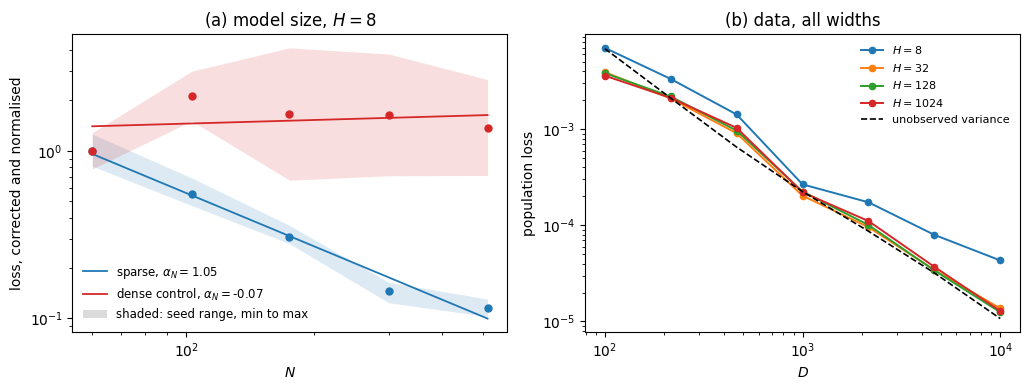

In [14]:
require(7)
from matplotlib.patches import Patch
flo = np.array([[var[rng_for(22, s*1000+int(D)).multinomial(int(D), p) == 0].sum()
                 for D in D_LADDER] for s in range(SEEDS)])

def pl(axis, x, Y, color, label):
    '''Points, seed spread, and the least-squares power law fitted to them.'''
    Y  = np.asarray(Y); y = gm(Y); k = y[0]
    lx = np.log(np.asarray(x, float))
    cf = np.polyfit(lx, np.log(y), 1)
    axis.fill_between(x, Y.min(0)/k, Y.max(0)/k, color=color, alpha=.15, lw=0)
    axis.loglog(x, y/k, "o", ms=5, color=color)
    axis.loglog(x, np.exp(np.polyval(cf, lx))/k, "-", lw=1.3, color=color,
                label=f"{label}{-cf[0]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10.4, 4.0))

A = ax[0]
pl(A, N_FIT, sF/infl, "C0", r"sparse, $\alpha_N=$")
pl(A, N_FIT, dF/infl, "C3", r"dense control, $\alpha_N=$")
A.set(xlabel="$N$", ylabel="loss, corrected and normalised",
      title=f"(a) model size, $H={H_C}$")
_h, _l = A.get_legend_handles_labels()
_h.append(Patch(facecolor="0.45", alpha=.25, lw=0))
_l.append(f"shaded: seed range, min to max")
A.legend(_h, _l, frameon=False, fontsize=8.5)

B = ax[1]
for H in WIDTHS:
    B.loglog(D_LADDER, gm(resD[H]), "o-", ms=4.5, lw=1.4, label=f"$H={H}$")
B.loglog(D_LADDER, gm(flo), "k--", lw=1.2, label="unobserved variance")
B.set(xlabel="$D$", ylabel="population loss", title="(b) data, all widths")
B.legend(frameon=False, fontsize=8)

fig.tight_layout(); fig.savefig("tangent_pile.pdf", bbox_inches="tight"); plt.show()
done(8)

## 10. Store inventory

What is on disk, for the record. Everything was written by `stash()` as it was
produced; this cell only reads.

In [15]:
require(5, 6)
z = load_store()
print(f"{os.path.abspath(STORE)}  ({os.path.getsize(STORE)/1e6:.2f} MB)")
for k in sorted(z):
    print(f"   {k:12s} {str(z[k].shape):>10s}  {z[k].dtype}")

/content/drive/MyDrive/alphaN_ckpt/tangent_sweeps.npz  (0.00 MB)
   D_CTRL               ()  int64
   D_LADDER           (7,)  int64
   H_C                  ()  int64
   K_N                  ()  float64
   N_CTRL               ()  int64
   N_LADDER           (7,)  int64
   N_L_C              (6,)  int64
   WIDTHS             (4,)  int64
   dN               (2, 6)  float64
   mask               (7,)  bool
   resD_1024        (3, 7)  float64
   resD_128         (3, 7)  float64
   resD_32          (3, 7)  float64
   resD_8           (3, 7)  float64
   sN               (3, 6)  float64
